# Softmax attention experiments

# My Custom Experiments

In the previous sections I have attempted to re-produce experiments from Gatmiry et al. In the following sections, I will implement several experiments that apply different assumptions and test the theoretical bounds of this paper. These were not written in the original paper.

In [1]:
# Imports and setup

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from experiments_helper import (
    run_experiment_suite,
    compute_loss_dict,
    compute_looped_loss_by_loop_count,
    compute_dist_dict,
    plot_loss_curves,
    plot_parameter_matrices,
    plot_dist_to_identity,
    plot_loop_loss_curves,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [2]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

Running on device: cuda.


In [3]:
# Final experiment: repeat the layered/looped sweep with softmax attention.
# This uses the same seeds, counts, data mode, optimizer, training steps, and
# reusable loss/distance/parameter plotting helpers as the baseline experiment.
softmax_attention_type = 'softmax'
softmax_seeds = [0]
softmax_counts = [1, 2, 5, 10]
softmax_model_types = ['looped']
softmax_context_lengths = [N]
softmax_data_modes = [normal_data_mode]
softmax_iterations = np.arange(0, max_iters, stride)

softmax_fig_dir = os.path.join('figures', 'softmax_attention')
os.makedirs(softmax_fig_dir, exist_ok=True)
softmax_history_file = os.path.join(
    cur_dir, f'softmax_attention_N{N}_d{d}_histories.pth')
softmax_results_file = os.path.join(
    cur_dir, f'softmax_attention_N{N}_d{d}_results.pth')

softmax_hist_dict = run_experiment_suite(
    seeds=softmax_seeds,
    n_layers_loops=softmax_counts,
    model_types=softmax_model_types,
    filename=softmax_history_file,
    context_lengths=softmax_context_lengths,
    data_modes=softmax_data_modes,
    head_counts=[n_head],
    attention_type=softmax_attention_type,
    freeze_p=True,  # [P-FIX] paper's P = [[0, 0], [0, 1]]
)
softmax_loss_dict = compute_loss_dict(
    softmax_hist_dict,
    test_seed=TEST_SEED,
    attention_type=softmax_attention_type,
)
softmax_dist_dict = compute_dist_dict(
    softmax_hist_dict,
    softmax_iterations,
    n_head=n_head,
    hist_stride=hist_stride,
)

torch.save(
    {
        'config': {
            'N': N, 'd': d, 'B': B, 'n_head': n_head,
            'attention_type': softmax_attention_type,
            'data_modes': softmax_data_modes,
            'seeds': softmax_seeds, 'counts': softmax_counts,
            'model_types': softmax_model_types,
            'alg': alg, 'lr': lr, 'clip_r': clip_r, 'var': var,
            'max_iters': max_iters, 'hist_stride': hist_stride,
            'stride': stride, 'test_seed': TEST_SEED,
        },
        'history_file': softmax_history_file,
        'hist_dict': softmax_hist_dict,
        'loss_dict': softmax_loss_dict,
        'distance_dict': softmax_dist_dict,
        'iterations': softmax_iterations,
    },
    softmax_results_file,
)
print(f'Saved softmax-attention experiment results to {softmax_results_file}')

Run 1/4: seed=0, count=1, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=softmax, freeze_p=True
iter 0 | Loss: 5.776828289031982 | time: 0.23613238334655762 | gradnorm: 1.8895063400268555
iter 1 | Loss: 5.397849082946777 | time: 0.0037453174591064453 | gradnorm: 1.7578399181365967
iter 2 | Loss: 5.658379077911377 | time: 0.0030095577239990234 | gradnorm: 1.881494164466858
iter 3 | Loss: 5.530811309814453 | time: 0.002714872360229492 | gradnorm: 1.8153581619262695
iter 4 | Loss: 5.34583854675293 | time: 0.002670764923095703 | gradnorm: 1.739263653755188
iter 100 | Loss: 4.9466094970703125 | time: 0.0033397674560546875 | gradnorm: 1.6439884901046753
iter 200 | Loss: 4.927915096282959 | time: 0.003064393997192383 | gradnorm: 1.5841126441955566
iter 300 | Loss: 4.801476955413818 | time: 0.0029249191284179688 | gradnorm: 1.4901533126831055
iter 400 | Loss: 4.20437479019165 | time: 0.0025033950805664062 | gradno

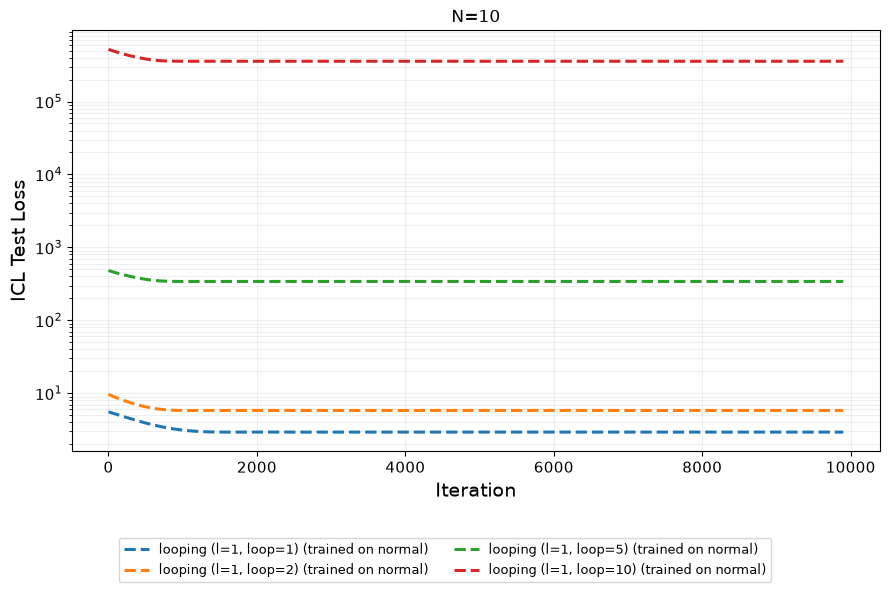

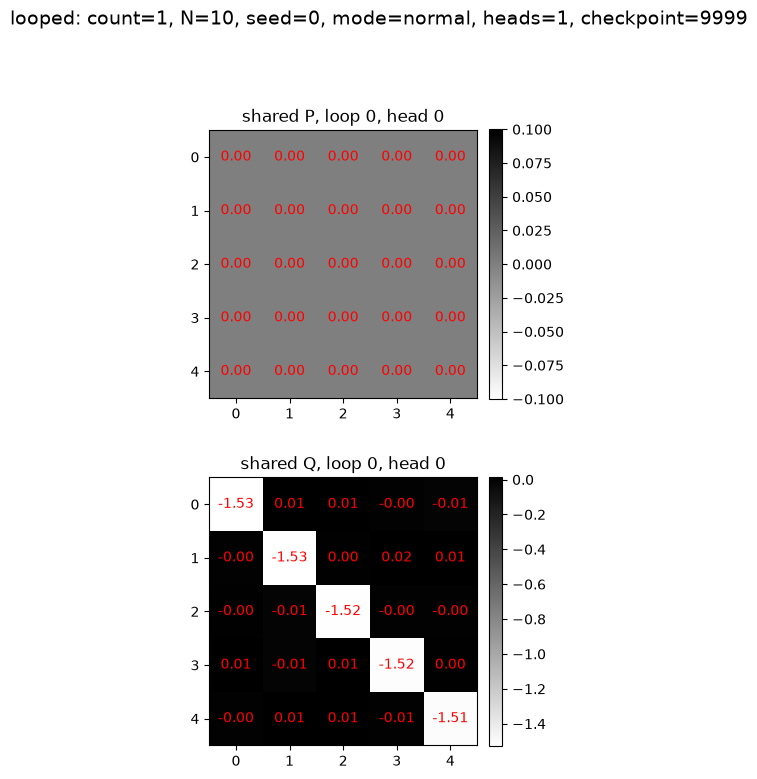

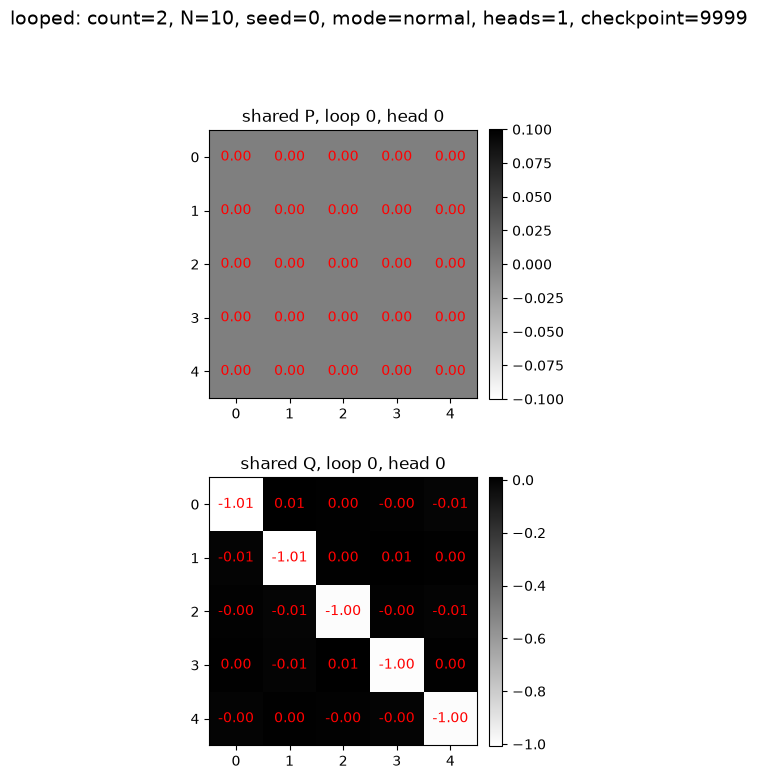

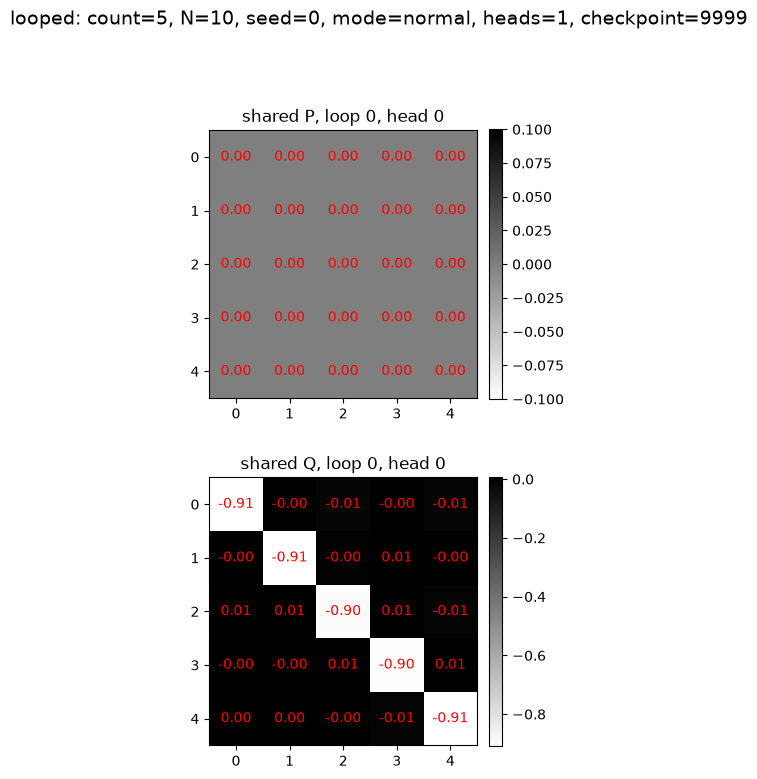

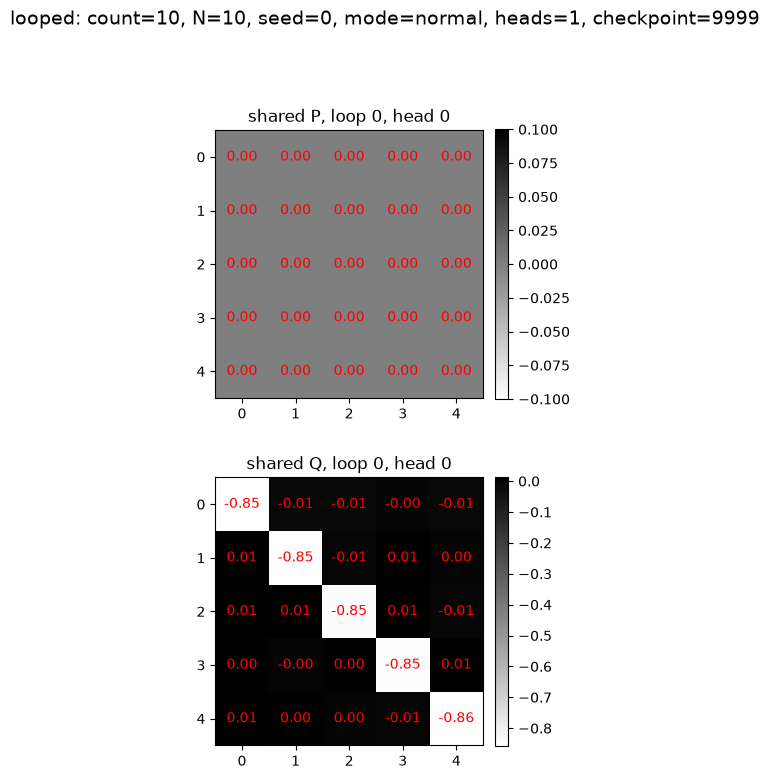

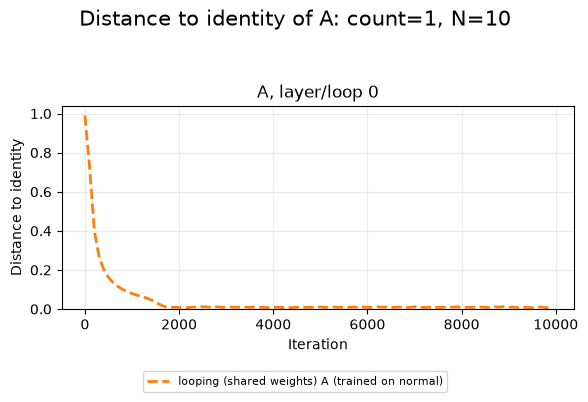

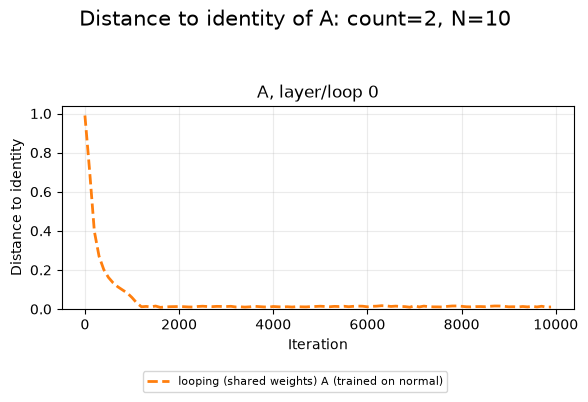

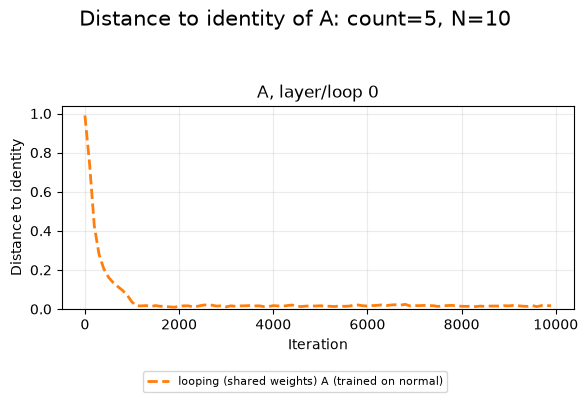

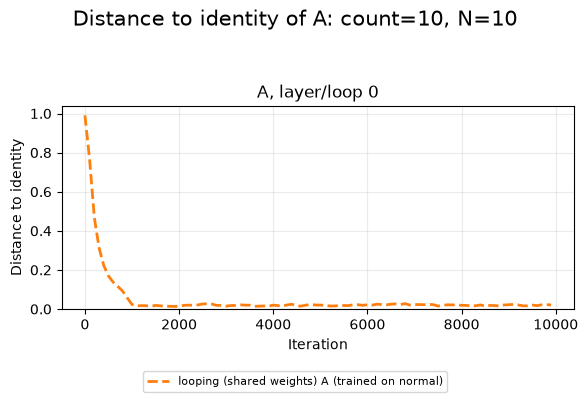

In [4]:
plot_loss_curves(
    softmax_loss_dict,
    softmax_counts,
    softmax_model_types,
    softmax_iterations,
    fig_dir=softmax_fig_dir,
    filename='softmax_test_loss_layered_vs_looped.pdf',
)
plot_parameter_matrices(
    softmax_hist_dict,
    softmax_seeds[0],
    softmax_counts,
    softmax_model_types,
    n_head,
    hist_stride=hist_stride,
    fig_dir=softmax_fig_dir,
)
plot_dist_to_identity(
    softmax_dist_dict,
    softmax_counts,
    softmax_iterations,
    fig_dir=softmax_fig_dir,
)

Testing: (0, 1, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax')
Evaluated checkpoint (0, 1, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax') through 50 loops.
Testing: (0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax')
Evaluated checkpoint (0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax') through 50 loops.
Testing: (0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax')
Evaluated checkpoint (0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax') through 50 loops.
Testing: (0, 10, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax')
Evalua

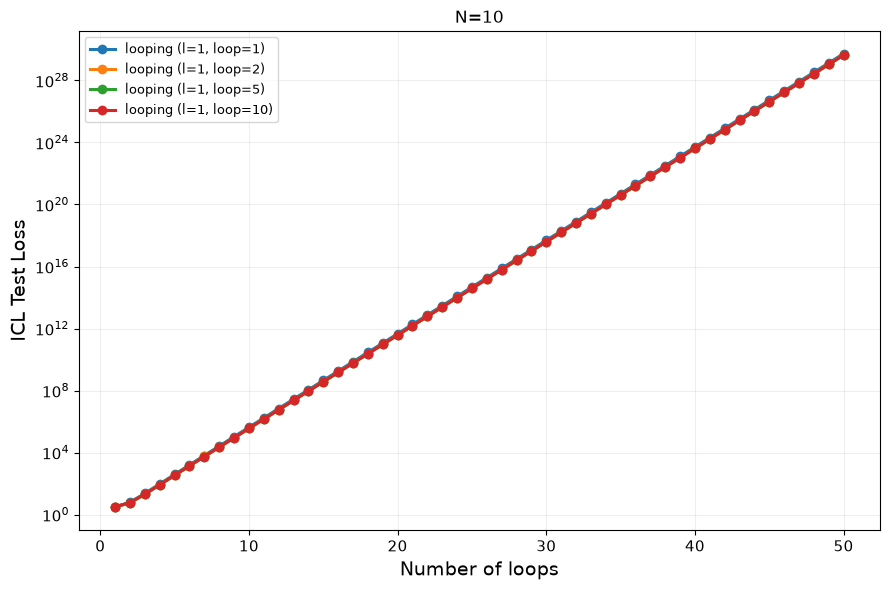

Saved softmax loop-count results to log/softmax_attention_loop_count_N10_d5_results.pth


In [5]:
# Evaluate final softmax looped checkpoints with 1 through 50 inference loops.
softmax_looped_hist_dict = {
    key: history
    for key, history in softmax_hist_dict.items()
    if key[2] == 'looped' and key[-1] == 'softmax'
}

softmax_max_loops = 50
softmax_loop_loss_dict = compute_looped_loss_by_loop_count(
    softmax_looped_hist_dict,
    max_loops=softmax_max_loops,
    test_seed=TEST_SEED,
    attention_type='softmax',
)

softmax_loop_results_file = os.path.join(
    cur_dir, f'softmax_attention_loop_count_N{N}_d{d}_results.pth',
)
torch.save({
    'max_loops': softmax_max_loops,
    'test_seed': TEST_SEED,
    'attention_type': 'softmax',
    'loss_dict': softmax_loop_loss_dict,
}, softmax_loop_results_file)

plot_loop_loss_curves(
    softmax_loop_loss_dict,
    n_layers_loops=softmax_counts,
    loop_counts=range(1, softmax_max_loops + 1),
    fig_dir=softmax_fig_dir,
    filename='softmax_test_loss_vs_loop_count.pdf',
)
print(f'Saved softmax loop-count results to {softmax_loop_results_file}')